In [1]:
from fastai.vision.all import *
path = untar_data(URLs.PETS)/'images'



KeyboardInterrupt: 

In [13]:
path

Path('/root/.fastai/data/oxford-iiit-pet/images')

In [4]:
def is_cat(x):
  return x[0].isupper() # gets targets or labels based on the file name
dls = ImageDataLoaders.from_name_func(
    path, 
    get_image_files(path), 
    valid_pct=0.2, # hold out 20% of data for validation
    seed=42,
    label_func=is_cat, 
    item_tfms=Resize(224) #predefined Transforms thta resizes each item to a 224 pixel square
)

learn = cnn_learner(dls, resnet34, metrics=error_rate)
learn.fine_tune(1)

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 155MB/s] 


epoch,train_loss,valid_loss,error_rate,time
0,0.163345,0.024272,0.010149,00:26


epoch,train_loss,valid_loss,error_rate,time
0,0.059436,0.027415,0.006089,00:32


In [5]:
import ipywidgets as widgets
from fastai.vision.all import PILImage

uploader = widgets.FileUpload()
display(uploader)

FileUpload(value=(), description='Upload')

In [14]:
uploaded_file = uploader.value[0]

img = PILImage.create(bytes(uploaded_file["content"]))

is_cat, _, probs = learn.predict(img)

print(f"Is this a cat?: {is_cat}.")
print(f"Probability: {probs[1].item():.6f}")

Is this a cat?: False.
Probability: 0.000000


In [7]:
print(learn.dls.vocab)

[False, True]


In [8]:
idx = probs.argmax()

print("Predicted breed:", dls.vocab[idx])
print("Probability:", probs[idx].item())

Predicted breed: True
Probability: 1.0


# **is it a brid?**

In [2]:
#NB: Kaggle requires phone verification to use the internet or a GPU. If you haven't done that yet, the cell below will fail
#    This code is only here to check that your internet is enabled. It doesn't do anything else.
#    Here's a help thread on getting your phone number verified: https://www.kaggle.com/product-feedback/135367

import socket,warnings
try:
    socket.setdefaulttimeout(1)
    socket.socket(socket.AF_INET, socket.SOCK_STREAM).connect(('1.1.1.1', 53))
except socket.error as ex: raise Exception("STOP: No internet. Click '>|' in top right and set 'Internet' switch to on")

In 2015 the idea of creating a computer system that could recognise birds was considered so outrageously challenging that it was the basis of [this XKCD joke](https://xkcd.com/1425/):

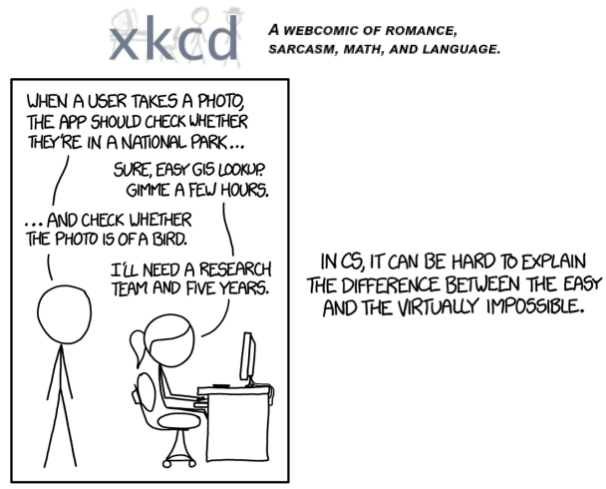

But today, we can do exactly that, in just a few minutes, using entirely free resources!

The basic steps we'll take are:

1. Use DuckDuckGo to search for images of "bird photos"
1. Use DuckDuckGo to search for images of "forest photos"
1. Fine-tune a pretrained neural network to recognise these two groups
1. Try running this model on a picture of a bird and see if it works.

## Step 1: Download images of birds and non-birds

In [3]:
from fastai.vision.all import *
from ddgs import DDGS

In [6]:
from ddgs import DDGS #DuckDuckGo has changed the api so we need to update 
from fastcore.all import *

def search_images(keywords, max_images=200): return L(DDGS().images(keywords, max_results=max_images)).itemgot('image')
import time, json

Let's start by searching for a bird photo and seeing what kind of result we get. We'll start by getting URLs from a search:

In [7]:
#NB: `search_images` depends on duckduckgo.com, which doesn't always return correct responses.
#    If you get a JSON error, just try running it again (it may take a couple of tries).
urls = search_images('bird photos', max_images=1)
urls[0]

'https://images.unsplash.com/photo-1552728089-57bdde30beb3?fm=jpg&q=60&w=3000&ixlib=rb-4.1.0&ixid=M3wxMjA3fDB8MHxzZWFyY2h8NHx8YmlyZHxlbnwwfHwwfHx8MA=='

...and then download a URL and take a look at it:

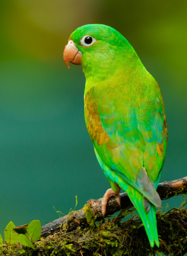

In [8]:
from fastdownload import download_url
dest = 'bird.jpg'
download_url(urls[0], dest, show_progress=False)

from fastai.vision.all import *
im = Image.open(dest)
im.to_thumb(256,256)

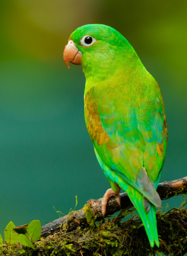

In [10]:
#from fastdownload import download_url
#dest = 'bird.jpg'
#download_url(urls[0], dest, show_progress=False)

from fastai.vision.all import *
im = Image.open(dest)
im.to_thumb(256,256)

Now let's do the same with "forest photos":

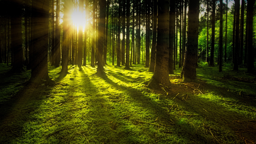

In [9]:
download_url(search_images('forest photos', max_images=1)[0], 'forest.jpg', show_progress=False)
Image.open('forest.jpg').to_thumb(256,256)

Our searches seem to be giving reasonable results, so let's grab a few examples of each of "bird" and "forest" photos, and save each group of photos to a different folder:

In [11]:
#searches = 'forest','bird'
#path = Path('bird_or_not')

#for o in searches:
    #dest = (path/o)
    #dest.mkdir(exist_ok=True, parents=True)
   # download_images(dest, urls=search_images(f'{o} photo'))
    #time.sleep(5)
   # resize_images(path/o, max_size=400, dest=path/o)

## Step 2: Train our model

Some photos might not download correctly which could cause our model training to fail, so we'll remove them:

In [12]:
failed = verify_images(get_image_files(path))
failed.map(Path.unlink)
len(failed)

1

To train a model, we'll need `DataLoaders`, which is an object that contains a *training set* (the images used to create a model) and a *validation set* (the images used to check the accuracy of a model -- not used during training). In `fastai` we can create that easily using a `DataBlock`, and view sample images from it:

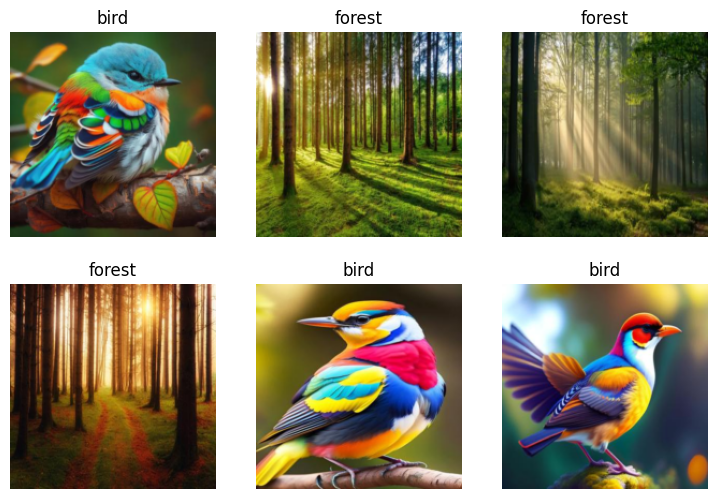

In [13]:
dls = DataBlock(
    blocks=(ImageBlock, CategoryBlock), 
    get_items=get_image_files, 
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=[Resize(192, method='squish')]
).dataloaders(path, bs=32)

dls.show_batch(max_n=6)

Here what each of the `DataBlock` parameters means:

    blocks=(ImageBlock, CategoryBlock),

The inputs to our model are images, and the outputs are categories (in this case, "bird" or "forest").

    get_items=get_image_files, 

To find all the inputs to our model, run the `get_image_files` function (which returns a list of all image files in a path).

    splitter=RandomSplitter(valid_pct=0.2, seed=42),

Split the data into training and validation sets randomly, using 20% of the data for the validation set.

    get_y=parent_label,

The labels (`y` values) is the name of the `parent` of each file (i.e. the name of the folder they're in, which will be *bird* or *forest*).

    item_tfms=[Resize(192, method='squish')]

Before training, resize each image to 192x192 pixels by "squishing" it (as opposed to cropping it).

Now we're ready to train our model. The fastest widely used computer vision model is `resnet18`. You can train this in a few minutes, even on a CPU! (On a GPU, it generally takes under 10 seconds...)

`fastai` comes with a helpful `fine_tune()` method which automatically uses best practices for fine tuning a pre-trained model, so we'll use that.

In [14]:
learn = vision_learner(dls, resnet18, metrics=error_rate)
learn.fine_tune(3)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 216MB/s]


epoch,train_loss,valid_loss,error_rate,time
0,1.638775,0.923656,0.416667,00:02


epoch,train_loss,valid_loss,error_rate,time
0,1.206849,0.680046,0.250000,00:00
1,0.897857,0.432740,0.083333,00:00
2,0.720902,0.357315,0.083333,00:00


Generally when I run this I see 100% accuracy on the validation set (although it might vary a bit from run to run).

"Fine-tuning" a model means that we're starting with a model someone else has trained using some other dataset (called the *pretrained model*), and adjusting the weights a little bit so that the model learns to recognise your particular dataset. In this case, the pretrained model was trained to recognise photos in *imagenet*, and widely-used computer vision dataset with images covering 1000 categories) For details on fine-tuning and why it's important, check out the [free fast.ai course](https://course.fast.ai/).

## Step 3: Use our model (and build your own!)

Let's see what our model thinks about that bird we downloaded at the start:

In [15]:
is_bird,_,probs = learn.predict(PILImage.create('bird.jpg'))
print(f"This is a: {is_bird}.")
print(f"Probability it's a bird: {probs[0]:.4f}")

This is a: bird.
Probability it's a bird: 0.9992


Good job, resnet18. :)

So, as you see, in the space of a few years, creating computer vision classification models has gone from "so hard it's a joke" to "trivially easy and free"!

It's not just in computer vision. Thanks to deep learning, computers can now do many things which seemed impossible just a few years ago, including [creating amazing artworks](https://openai.com/dall-e-2/), and [explaining jokes](https://www.datanami.com/2022/04/22/googles-massive-new-language-model-can-explain-jokes/). It's moving so fast that even experts in the field have trouble predicting how it's going to impact society in the coming years.

One thing is clear -- it's important that we all do our best to understand this technology, because otherwise we'll get left behind!

Now it's your turn. Click "Copy & Edit" and try creating your own image classifier using your own image searches!

If you enjoyed this, please consider clicking the "upvote" button in the top-right -- it's very encouraging to us notebook authors to know when people appreciate our work.

# **train a segmentation mo l with astai, using a subset of CamVid dataset**

In [1]:
from fastai.vision.all import *

In [ ]:
path = untar_data(URLs.CAMVID_TINY)
dls = SegmentationDataLoaders.from_label_func( 
    path, bs=8, fnames = get_image_files(path/"images"), 
    label_func = lambda o: path/'labels'/f'{o.stem}_P{o.suffix}', 
    codes = np.loadtxt(path/'codes.txt', dtype=str)
) 

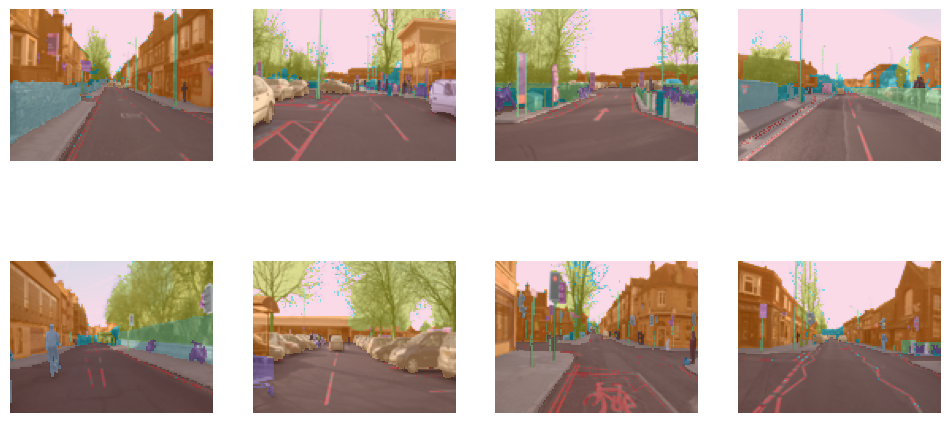

In [14]:
dls.show_batch(max_n=8)

In [17]:
learn = unet_learner(dls, resnet34)
learn.fine_tune(8)

epoch,train_loss,valid_loss,time
0,2.877423,3.358947,00:01


epoch,train_loss,valid_loss,time
0,2.051537,1.756816,00:01
1,1.771624,1.508810,00:01
2,1.600044,1.231345,00:01
3,1.440551,1.124392,00:01
4,1.288308,0.922408,00:01
5,1.167087,0.885486,00:01
6,1.063794,0.843019,00:01
7,0.983488,0.830181,00:01


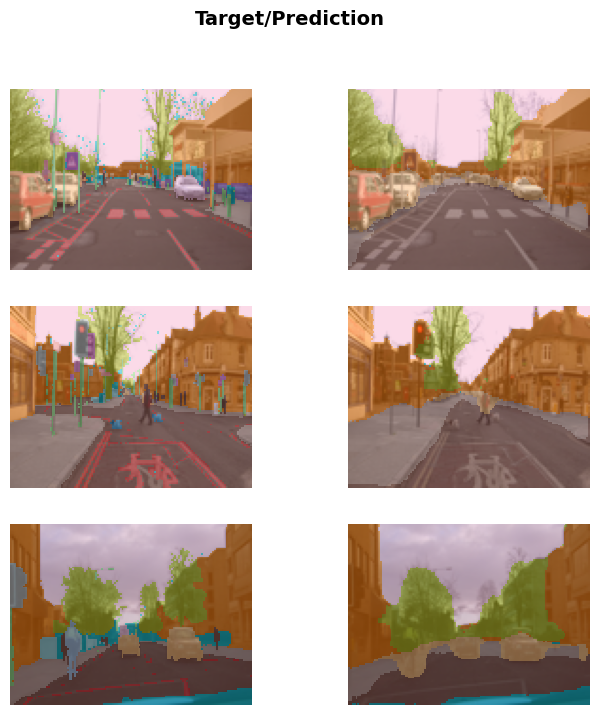

In [18]:
learn.show_results(max_n=3, figsize=(8,8))


##  **Classify sentiment for a movie review**

In [31]:
from fastai.text.all import *

dls=TextDataLoaders.from_folder(
    untar_data(URLs.IMDB), 
    valid='test')

                              

In [33]:

learn= text_classifier_learner(
    dls,
    AWD_LSTM, 
    drop_mult=0.5,
    metrics=accuracy
)

<div><progress max="105067061" value="105070592"></progress> 100.00% [105070592/105067061 00:02&lt;00:00]</div>

In [34]:
learn.fine_tune(4,1e-2)

epoch,train_loss,valid_loss,accuracy,time
0,0.471003,0.384042,0.828720,03:51


epoch,train_loss,valid_loss,accuracy,time
0,0.331317,0.325019,0.850960,08:12
1,0.232717,0.205686,0.919560,08:11
2,0.194065,0.186331,0.929600,08:13
3,0.159096,0.189394,0.929720,08:13


In [54]:
learn.predict("I really liked that movie!")

('pos', tensor(1), tensor([3.8447e-04, 9.9962e-01]))

In [65]:
sentences = [
    "I really liked that movie!",
    "The movie was boring and I couldn't finish it.",
    "The acting was excellent and the story was amazing!",
    " I didnt like it"
]

for sentence in sentences:
    prediction, class_idx, probabilities = learn.predict(sentence)

    print(f"Review: {sentence}")
    print(f"Sentiment: {prediction.upper()}")
    print(f"Negative probability: {probabilities[0].item():.2%}")
    print(f"Positive probability: {probabilities[1].item():.2%}")
    print("-" * 50)

Review: I really liked that movie!
Sentiment: POS
Negative probability: 0.04%
Positive probability: 99.96%
--------------------------------------------------


Review: The movie was boring and I couldn't finish it.
Sentiment: NEG
Negative probability: 99.98%
Positive probability: 0.02%
--------------------------------------------------


Review: The acting was excellent and the story was amazing!
Sentiment: POS
Negative probability: 0.66%
Positive probability: 99.34%
--------------------------------------------------


Review:  I didnt like it
Sentiment: POS
Negative probability: 1.35%
Positive probability: 98.65%
--------------------------------------------------


## **Building models from tabular data**

In [2]:
from fastai.tabular.all import *
path = untar_data(URLs.ADULT_SAMPLE)

<div><progress max="968212" value="974848"></progress> 100.69% [974848/968212 00:01&lt;00:00]</div>

In [3]:
dls =TabularDataLoaders.from_csv(
    path/'adult.csv',
    path=path, 
    y_names ="salary",
    cat_names = ['workclass','education','marital-status','occupation','relationship','race'],
    cont_names= ['age','fnlwgt','education-num'],
    procs=[Categorify,FillMissing,Normalize]
)


/usr/local/lib/python3.12/dist-packages/fastai/tabular/core.py:314: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  to[n].fillna(self.na_dict[n], inplace=True)


In [6]:
learn= tabular_learner(dls,metrics=accuracy)

In [16]:
learn.fine_tune(3) # Used for tabular data since it doesnt make sense to fine tune () cos datasest are diff unlike images

epoch,train_loss,valid_loss,accuracy,time
0,0.362133,0.357606,0.834459,00:04


epoch,train_loss,valid_loss,accuracy,time
0,0.352522,0.355605,0.835534,00:04
1,0.362559,0.350674,0.840141,00:04
2,0.362243,0.348192,0.843520,00:04


In [17]:
learn.show_results()

,workclass,education,marital-status,occupation,relationship,race,education-num_na,age,fnlwgt,education-num,salary,salary_pred
0,5.0,15.0,5.0,11.0,2.0,5.0,1.0,0.760200,-1.379556,1.925747,1.0,1.0
1,5.0,12.0,5.0,7.0,5.0,5.0,1.0,-1.068787,1.059362,-0.425717,0.0,0.0
2,5.0,16.0,6.0,11.0,5.0,5.0,1.0,-0.410352,-0.096684,-0.033807,0.0,0.0
3,5.0,16.0,3.0,13.0,1.0,5.0,1.0,-0.483511,-0.614292,-0.033807,0.0,0.0
4,5.0,10.0,3.0,5.0,6.0,5.0,1.0,-0.190873,1.599826,1.141925,0.0,1.0
5,5.0,12.0,5.0,4.0,2.0,5.0,1.0,-1.288265,-1.048237,-0.425717,0.0,0.0
6,1.0,2.0,3.0,1.0,4.0,3.0,1.0,0.833359,-0.310643,-1.209538,0.0,0.0
7,8.0,13.0,5.0,11.0,2.0,5.0,1.0,-0.483511,3.076161,1.533836,0.0,0.0
8,7.0,10.0,3.0,13.0,6.0,5.0,1.0,-0.117714,-0.804182,1.141925,0.0,1.0


In [18]:
import pandas as pd
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

df = pd.read_csv("/kaggle/input/datasets/hunterxwolf/adult-sample-data/adult_census_samples.csv")

# Predict the whole CSV at once
test_dl = learn.dls.test_dl(df)
preds, _ = learn.get_preds(dl=test_dl)

# Map the predictions to the actual labels
df['predicted_income'] = [learn.dls.vocab[p.argmax().item()] for p in preds]

# Display a clean dataframe showing the relevant columns
print(df[['age', 'occupation', 'predicted_income']].to_string())

    age         occupation predicted_income
0    35    Exec-managerial            >=50k
1    28       Craft-repair             <50k
2    42     Prof-specialty            >=50k
3    22       Adm-clerical             <50k
4    55              Sales             <50k
5    31    Protective-serv             <50k
6    48     Prof-specialty            >=50k
7    25  Machine-op-inspct             <50k
8    39    Exec-managerial            >=50k
9    60     Prof-specialty            >=50k
10   29              Sales             <50k
11   45   Transport-moving             <50k
12   33    Exec-managerial            >=50k
13   21      Other-service             <50k
14   51    Farming-fishing             <50k
15   38       Tech-support             <50k
16   27       Craft-repair             <50k
17   65     Prof-specialty             <50k
18   34  Handlers-cleaners             <50k
19   41    Exec-managerial            >=50k
20   23              Sales             <50k
21   47       Adm-clerical      

## **Recommedation systems** 

In [31]:
from fastai.vision.all import *

from ddgs import DDGS #DuckDuckGo has changed the api so we need to update 
from fastcore.all import *

def search_images(keywords, max_images=200): 
    return L(DDGS().images(keywords, max_results=max_images)).itemgot('image')
import time, json

In [4]:
search_images

<function __main__.search_images(keywords, max_images=200)>

In [5]:
results = search_images
#NB: `search_images` depends on duckduckgo.com, which doesn't always return correct responses.
#    If you get a JSON error, just try running it again (it may take a couple of tries).
urls = search_images('Crocodile', max_images=1)
urls[0]

'https://cdn.wallpapersafari.com/52/98/UGf2Ay.jpg'

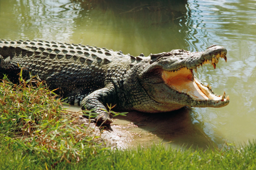

In [6]:
from fastdownload import download_url
dest = 'Crocodile.png'
download_url(urls[0], dest, show_progress=False)

from fastai.vision.all import *
im = Image.open(dest)
im.to_thumb(256,256)

In [7]:
#searches = 'Crocodile','Alligator','Agama Lizard'
#path = Path('images')

#for o in searches:
    #dest = (path/o)
    #dest.mkdir(exist_ok=True, parents=True)
    #download_images(dest, urls=search_images(f'{o} photo'))
    #time.sleep(5)
   # resize_images(path/o, max_size=400, dest=path/o)

In [159]:
from pathlib import Path
import time

# Map your folder names to specific, distinct search queries
categories = {
        'Crocodile': ['Nile Crocodile photo in the wild', 'Saltwater Crocodile photo'],
        'Alligator': ['American Alligator photo in the wild', 'Chinese Alligator photo'],
        'Agama Lizard': ['Agama Lizard photo']
}

path = Path('images')

for category, queries in categories.items():
    dest = (path/category)
    dest.mkdir(exist_ok=True, parents=True)
    
    # Loop through each specific query for the category
    for q in queries:
        print(f"Downloading {q} into {category}...")
        download_images(dest, urls=search_images(q))
        time.sleep(5) # Pause to avoid hitting search engine rate limits
        
    # Resize all downloaded images in the folder
    resize_images(dest, max_size=400, dest=dest)

In [190]:
fns = get_image_files(path)
fns

(#657) [Path('Crocodile.png'), Path('images/Agama Lizard/6d6975a6-c829-4889-a543-a17fda576df4.jpg'), Path('images/Agama Lizard/f5ed685f-0c78-446c-88d5-3c9681dd1098.jpg'), Path('images/Agama Lizard/6204dba5-bfbd-4e97-ad18-9a356a4325f2.jpg'), Path('images/Agama Lizard/e0831f85-8006-4348-a479-6ad3d4e9bc6c.jpg'), Path('images/Agama Lizard/da285695-0dc7-4f27-acd1-e90d0147deaf.jpg'), Path('images/Agama Lizard/4f325365-a1de-41e3-8862-2259546f3dac.jpg'), Path('images/Agama Lizard/9c3ec43a-6216-435a-9231-150fb0969ef9.jpg'), Path('images/Agama Lizard/a9a12756-752b-47ab-97c1-fe1498ad9376.jpg'), Path('images/Agama Lizard/a66d8e10-3ea8-42aa-adcd-69193bc0a365.jpg'), Path('images/Agama Lizard/0bbb60e2-2b55-4b3f-9166-b8c87ff2752b.jpg'), Path('images/Agama Lizard/273954c8-3bce-408c-baa0-e48d8f3d30d9.jpg'), Path('images/Agama Lizard/a3152419-47f2-4b2f-a57b-cc1b7d76c170.jpg'), Path('images/Agama Lizard/c48c99ca-29b9-4963-b127-55e899e24416.jpg'), Path('images/Agama Lizard/2e54045d-fcca-45e1-8202-9dc7b9118

In [191]:
failed = verify_images(fns)
failed
failed.map(Path.unlink);

In [ ]:
?? verify_images

In [ ]:
%debug

In [ ]:
?? DataBlock

In [192]:
# creating dataloaders with fast.ai

reptiles=DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=[Resize(128, method='squish')] # squish or cropped can reduce model performance since 
    #image will be distorted or cropred out at certain sections- so the image of new without squish can fail
)

In [193]:
dls = reptiles.dataloaders(path)

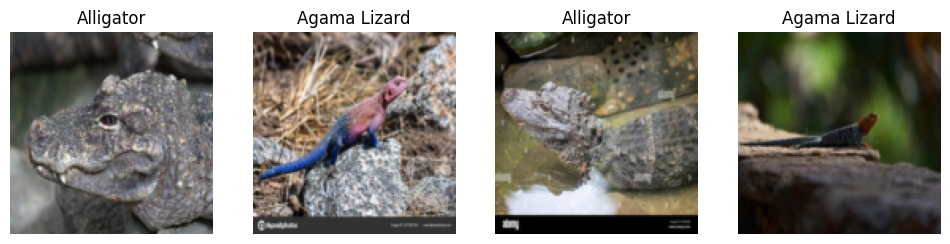

In [194]:
dls.valid.show_batch(max_n=4, nrows=1)

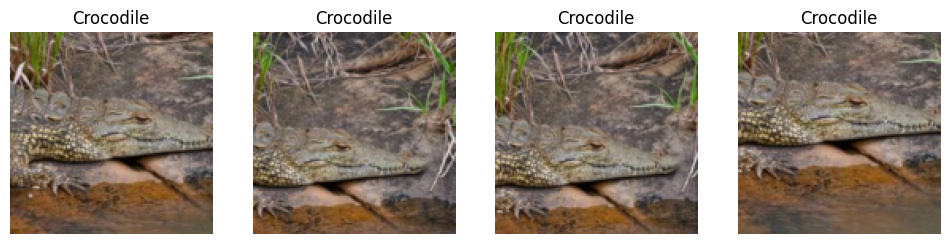

In [195]:
reptiles=reptiles.new(item_tfms=RandomResizedCrop(128, min_scale=0.3))
dls = reptiles.dataloaders(path)
dls.train.show_batch(max_n=4, nrows=1, unique=True)

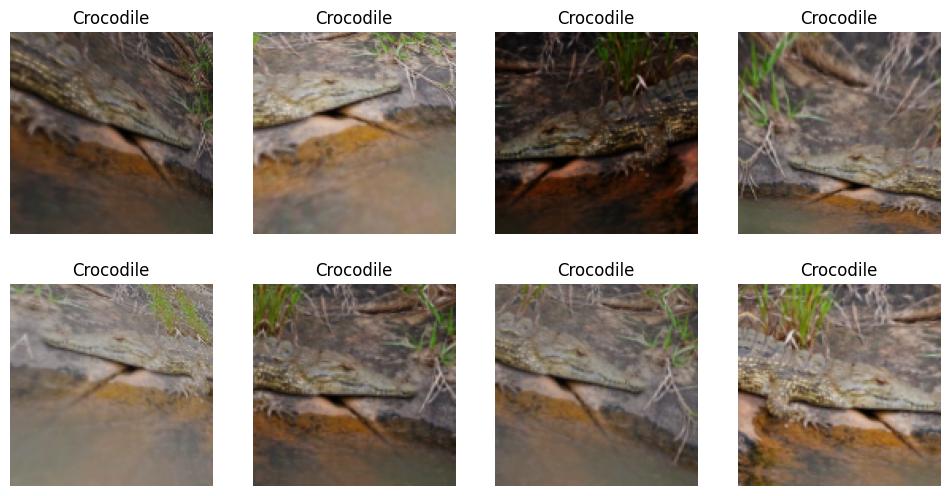

In [196]:
reptiles=reptiles.new(item_tfms=Resize(128),batch_tfms=aug_transforms(mult=2))
dls = reptiles.dataloaders(path)
dls.train.show_batch(max_n=8, nrows=2, unique=True)

In [197]:
reptiles=reptiles.new(item_tfms=RandomResizedCrop(224, min_scale=0.5), batch_tfms=aug_transforms())
dls = reptiles.dataloaders(path)


In [200]:
learn=vision_learner(dls, resnet18, metrics=error_rate)
learn.fine_tune(4)

epoch,train_loss,valid_loss,error_rate,time
0,1.748064,0.452392,0.167939,00:02


epoch,train_loss,valid_loss,error_rate,time
0,0.612312,0.255843,0.091603,00:02
1,0.457457,0.144988,0.045802,00:02
2,0.341007,0.140235,0.045802,00:03
3,0.271148,0.137876,0.045802,00:02


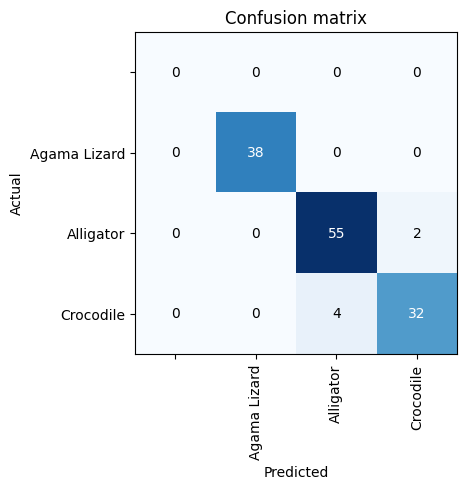

In [201]:
interp = ClassificationInterpretation.from_learner(learn) #use validation set to calc confusion matrix
interp.plot_confusion_matrix()

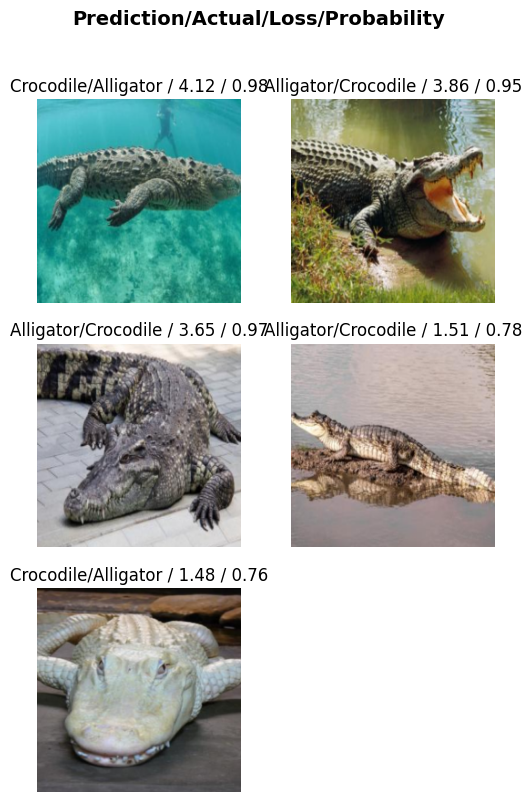

In [202]:
interp.plot_top_losses(5,nrows=3)
#Prediction / Actual / Loss / Probability

In [188]:
from fastai.vision.widgets import *
cleaner = ImageClassifierCleaner(learn)
cleaner

In [189]:
for idx in cleaner.delete(): 
    cleaner.fns[idx].unlink() #  to delete (unlink) all images selected for deletion, we would run
for idx,cat in cleaner.change(): 
    shutil.move(str(cleaner.fns[idx]),path/cat)# To move images for which we've selected a different category, we would run:


In [203]:
learn.export()

In [204]:
path=Path()
path.ls(file_exts=".pkl")

[Path('export.pkl')]

In [205]:
learn_inf=load_learner(path/'export.pkl')

/usr/local/lib/python3.12/dist-packages/fastai/learner.py:455: UserWarning: load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.
If you only need to load model weights and optimizer state, use the safe `Learner.load` instead.
  try:


In [206]:
learn_inf.dls.vocab

['', 'Agama Lizard', 'Alligator', 'Crocodile']

## **Creating a jupyter app based on model**

In [207]:
btn_upload=widgets.FileUpload()
btn_upload

FileUpload(value=(), description='Upload')

In [233]:
img = PILImage.create(btn_upload.value[-1].content.tobytes())


In [234]:
out_pl = widgets.Output()
out_pl.clear_output()
with out_pl: display(img.to_thumb(400,400))
out_pl


Output()

In [235]:
pred,pred_id,probs = learn_inf.predict(img)

In [236]:
lbl_pred = widgets.Label()
lbl_pred.value = f'Prediction: {pred}; Probability : {probs[pred_id ]:.04f}'
lbl_pred

Label(value='Prediction: Agama Lizard; Probability : 1.0000')

In [248]:
import ipywidgets as widgets
from IPython.display import display
from fastai.vision.all import PILImage

btn_upload = widgets.FileUpload(
    accept='image/*',
    multiple=False
)

btn_run = widgets.Button(
    description='Classify',
    button_style='success'
)

out_pl = widgets.Output()

lbl_pred = widgets.Label()

In [257]:
def on_click_classif(change):
    out_pl.clear_output()

    with out_pl:
        try:
            # Get uploaded file
            file = btn_upload.value[0]

            # Convert memoryview to bytes
            img_bytes = bytes(file['content'])

            # Create FastAI image
            img = PILImage.create(img_bytes)

            # Display image
            display(img.to_thumb(128, 128))

            # Make prediction
            pred, pred_id, probs = learn_inf.predict(img)

            # Display result
            lbl_pred.value = (
                f"Prediction: {pred}; "
                f"Probability: {probs[pred_id]:.4f}"
            )

        except Exception as e:
            lbl_pred.value = f"Error: {e}"


btn_run.on_click(on_click_classif)

In [258]:
VBox([
    widgets.Label('Select our bear!'),
    btn_upload,
    btn_run,
    out_pl,
    lbl_pred
])

# **CHAPTER II**

### ***Pixels***

In [1]:
from fastai.vision.all import *

#from ddgs import DDGS #DuckDuckGo has changed the api so we need to update 
from fastcore.all import *
import time, json

In [5]:
path=untar_data(URLs.MNIST_SAMPLE)

In [6]:
path.ls()

[Path('/root/.fastai/data/mnist_sample/valid'), Path('/root/.fastai/data/mnist_sample/labels.csv'), Path('/root/.fastai/data/mnist_sample/train')]

In [7]:
(path/'train').ls()

[Path('/root/.fastai/data/mnist_sample/train/7'), Path('/root/.fastai/data/mnist_sample/train/3')]

In [8]:
three=(path/'train'/'3').ls().sorted()
Seven=(path/'train'/'7').ls().sorted()

In [9]:
#three


###   *Using the Image class from the Python Imaging library(PIL), which is the most widely used Python package for opening,manipulatind and viewing images*


In [10]:
im3_path=three[1]
im3=Image.open(im3_path)
im3

In [11]:
torch.set_printoptions(linewidth=200, profile="full")
# to view image as a their numbers
#array(im3)[4:10,4:10] # to view from row 4 to row 9 and column 4 to 9

# or
tensor(im3)

tensor([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,  29, 150, 195, 254, 255, 254, 176, 193, 150,  96,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,  48, 166, 224, 253, 253, 234, 196, 253, 253, 253, 253, 2

In [12]:
im3_t=tensor(im3)
df=pd.DataFrame(im3_t[4:15,4:22])
df.style.set_properties(**{"font-size":"6pt"}).background_gradient('Greys')

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,29,150,195,254,255,254,176,193,150,96,0,0,0
2,0,0,0,48,166,224,253,253,234,196,253,253,253,253,233,0,0,0
3,0,93,244,249,253,187,46,10,8,4,10,194,253,253,233,0,0,0
4,0,107,253,253,230,48,0,0,0,0,0,192,253,253,156,0,0,0
5,0,3,20,20,15,0,0,0,0,0,43,224,253,245,74,0,0,0
6,0,0,0,0,0,0,0,0,0,0,249,253,245,126,0,0,0,0
7,0,0,0,0,0,0,0,14,101,223,253,248,124,0,0,0,0,0
8,0,0,0,0,0,11,166,239,253,253,253,187,30,0,0,0,0,0
9,0,0,0,0,0,16,248,250,253,253,253,253,232,213,111,2,0,0


In [13]:
im3_t=tensor(im3)
df=pd.DataFrame(im3_t[4:15,4:22])
df.style.set_properties(**{"font-size":"6pt"}).background_gradient('Greys')

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,29,150,195,254,255,254,176,193,150,96,0,0,0
2,0,0,0,48,166,224,253,253,234,196,253,253,253,253,233,0,0,0
3,0,93,244,249,253,187,46,10,8,4,10,194,253,253,233,0,0,0
4,0,107,253,253,230,48,0,0,0,0,0,192,253,253,156,0,0,0
5,0,3,20,20,15,0,0,0,0,0,43,224,253,245,74,0,0,0
6,0,0,0,0,0,0,0,0,0,0,249,253,245,126,0,0,0,0
7,0,0,0,0,0,0,0,14,101,223,253,248,124,0,0,0,0,0
8,0,0,0,0,0,11,166,239,253,253,253,187,30,0,0,0,0,0
9,0,0,0,0,0,16,248,250,253,253,253,253,232,213,111,2,0,0


In [14]:
im3.shape

(28, 28)

## *Python List Comprehensions*
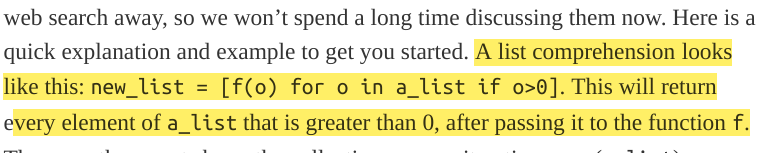

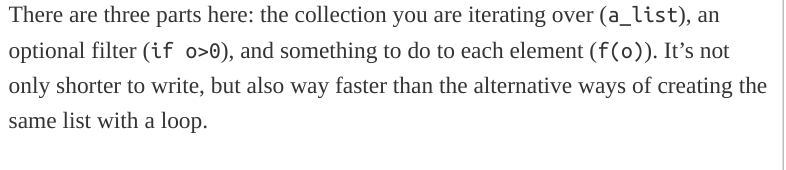

In [15]:
seven_tensors=[tensor(Image.open(o)) for o in Seven]
three_tensors=[tensor(Image.open(o)) for o in three] # new_list= [this_function(o) for o in this_current_list if o>0]

In [16]:
len(three_tensors),len(seven_tensors)

(6131, 6265)

<Axes: >

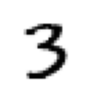

In [17]:
show_image(three_tensors[1],cmap='Grays')


In [18]:
#changing the uint8 to floats, by dividing by 255
stacked_seven_tensors=torch.stack(seven_tensors).float()/255
stacked_three_tensors=torch.stack(three_tensors).float()/255


stacked_seven_tensors.shape,stacked_three_tensors.shape


(torch.Size([6265, 28, 28]), torch.Size([6131, 28, 28]))

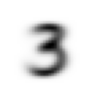

In [19]:
# computing mean for every pixel position (image)

mean3=stacked_three_tensors.mean(0)
show_image(mean3,cmap='Grays'); ## ideal 3 from all our 3's averaged

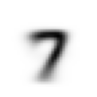

In [20]:

mean7=stacked_seven_tensors.mean(0)
show_image(mean7,cmap='Grays');

<Axes: >

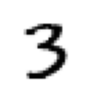

In [21]:
a_3=stacked_three_tensors[1]
show_image(a_3, cmap='Grays')

<Axes: >

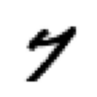

In [22]:
a_7=stacked_seven_tensors[1]
show_image(a_7, cmap='Grays')

In [23]:
# L1 Norm
dist_3_abs= (a_3-mean3).abs().mean()
#L2 Norm
dist_3_sqr= ((a_3-mean3)**2).mean().sqrt()

dist_3_abs,dist_3_sqr


(tensor(0.1114), tensor(0.2021))

In [24]:
# L1 Norm
dist_7_abs= (a_7-mean3).abs().mean()
#L2 Norm
dist_7_sqr= ((a_7-mean3)**2).mean().sqrt()

dist_7_abs,dist_7_sqr ## output is the distance between the selected 7 and ideal 7

(tensor(0.1854), tensor(0.3271))

In [25]:
F.l1_loss(a_3.float(),mean7),F.mse_loss(a_3.float(),mean7).sqrt() ### L2 Norm is also mse or rmse loss

(tensor(0.1586), tensor(0.3021))

## Summary: Understanding Vector Norms
A norm is a mathematical tool used to measure the length, size, or distance of a vector. Think of it as a smart ruler.
------------------------------
## 1. The Setup: The Environment

* Vector Space (V): A collection of objects (vectors) we want to measure, like a 2D grid.
* Field (F): The system of real or complex numbers used to stretch or shrink vectors.

------------------------------
## 2. The Ruler: The Function

* The Function (p): A mapping written as $p: V \rightarrow [0, +\infty)$.
* Nonnegative Output: You input a vector, and it outputs a distance. Distance can never be negative; it is always 0 or greater.

------------------------------
## 3. The Rules: What Makes it a Norm## Rule A: The Triangle Inequality (Subadditivity)

* Formula: p(u + v) ≤ p(u) + p(v)
* Concept: The shortest distance between two points is a straight line.
* Analogy: Taking a direct path (p(u+v)) is always shorter than or equal to taking a detour through a third point (p(u) + p(v)).

## Rule B: The Scaling Rule (Absolute Homogeneity)

* Formula: $p(au) = \vert{}a\vert{} \cdot p(u)$
* Concept: Scaling a vector by a factor (a) scales its measured length by the absolute value of that factor. Negative directions do not create negative lengths.

## Rule C: The Zero Rule (Positive Definiteness)

* Formula: If p(u) = 0, then u = 0
* Concept: The only object with a length of zero is the zero vector (no movement at all).



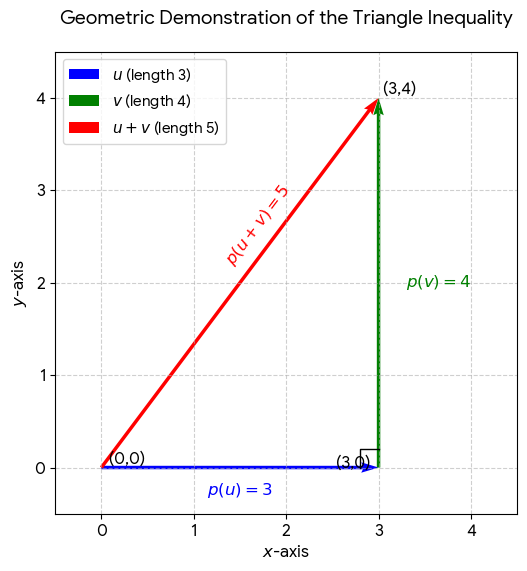
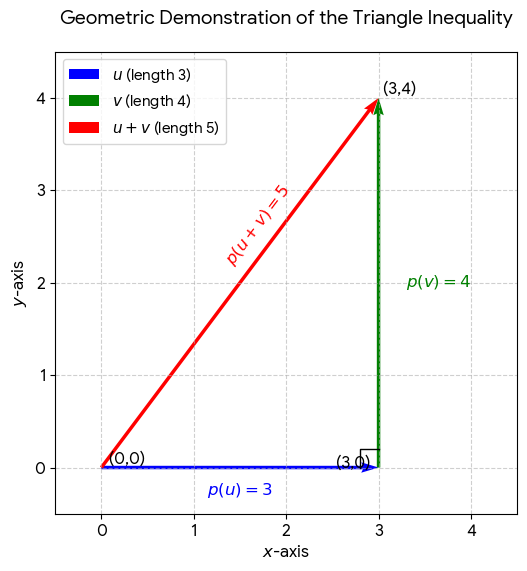

In [26]:
## testing our first try model on validation set
## this is a culminated version of the train code
valid_3_tensor=torch.stack([tensor(Image.open(o)) 
                         for o in (path/'valid'/'3').ls()])
valid_7_tensor=torch.stack([tensor(Image.open(o)) 
                         for o in (path/'valid'/'7').ls()])

valid_3_tensor=valid_3_tensor.float()/255
valid_7_tensor=valid_7_tensor.float()/255

valid_3_tensor.shape,valid_7_tensor.shape

(torch.Size([1010, 28, 28]), torch.Size([1028, 28, 28]))

In [27]:
## to determine distance(loss between two images)

def mnist_distance(a,b):
    return (a-b).abs().mean((-1,-2)) #used l1 norm (mae)

mnist_distance(a_3,mean3)

tensor(0.1114)

In [28]:
#validation Set
Valid_3_dist=mnist_distance(valid_3_tensor,mean3) #valid__tensor is 1010 samples and mean3 is on sample so how does subtracting them work--- Broadcasting
Valid_3_dist,Valid_3_dist.shape

(tensor([0.1270, 0.1632, 0.1676, 0.1058, 0.1214, 0.1358, 0.1159, 0.1270, 0.1667, 0.1224, 0.1133, 0.1493, 0.1242, 0.1242, 0.1198, 0.1356, 0.1633, 0.1087, 0.1405, 0.1240, 0.1202, 0.1388, 0.1109, 0.1766,
         0.1405, 0.1585, 0.1394, 0.1591, 0.1183, 0.1080, 0.1233, 0.1169, 0.1277, 0.1287, 0.1299, 0.1219, 0.1287, 0.1541, 0.1113, 0.1069, 0.1132, 0.1309, 0.1557, 0.1300, 0.1317, 0.1112, 0.1124, 0.1243,
         0.1433, 0.1230, 0.1411, 0.1229, 0.1373, 0.1125, 0.1192, 0.1407, 0.1320, 0.1225, 0.1280, 0.1412, 0.1360, 0.1100, 0.1207, 0.1100, 0.1413, 0.1470, 0.1156, 0.1130, 0.1130, 0.1169, 0.1217, 0.1248,
         0.1377, 0.1230, 0.1413, 0.1249, 0.1343, 0.1337, 0.1207, 0.1318, 0.1495, 0.1373, 0.1053, 0.1661, 0.1246, 0.1295, 0.1174, 0.1156, 0.1583, 0.1174, 0.1279, 0.1322, 0.1484, 0.1465, 0.1238, 0.1208,
         0.1342, 0.1421, 0.1244, 0.1440, 0.1333, 0.1142, 0.1107, 0.1160, 0.1120, 0.1061, 0.1380, 0.1349, 0.1530, 0.1070, 0.1578, 0.1446, 0.1173, 0.1137, 0.1134, 0.1321, 0.1170, 0.1267, 0.1326, 0.1

In [29]:
Valid_3_dist.shape

torch.Size([1010])

In [30]:


def is_3(x):
    return mnist_distance(x,mean3)< mnist_distance(x,mean7)

is_3(a_3), is_3(a_3).float()

(tensor(True), tensor(1.))

In [31]:
is_3(a_7), is_3(a_7).float()

(tensor(False), tensor(0.))

In [32]:
# on whole validation set
is_3(valid_3_tensor)

tensor([ True, False, False,  True,  True,  True,  True,  True,  True,  True,  True, False,  True,  True,  True,  True,  True,  True,  True,  True, False,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True, False,  True,  True,  True,  True,  True,  True,  True,  True,  True, False,  True,
         True, False, False,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True, False,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True, False,  True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True, False,  True,  True,  True,  True,  True,  True,  True,  True,  True, False,  True,  True,  True,  True,  True,  True, False,  True,  True,  True,  True,  True,  True,  True,
         True, 

In [33]:
accuracy_3s=is_3(valid_3_tensor).float().mean()
accuracy_7s=(1-is_3(valid_7_tensor).float()).mean()
accuracy_3s,accuracy_7s,(accuracy_3s+accuracy_7s)/2

(tensor(0.9168), tensor(0.9854), tensor(0.9511))

## **The above was for only two digit classification and not realistic *(since we have 10 digits irl)* and also this was coded (a program) no learning was done. To do for the multiple classfication we need some learning and this will be acheived by using SGD's**

# An End-to-End SGD Example

In [34]:
from fastai import *
import time as time
from fastai.vision.all import *


from fastcore.all import *

In [35]:
time=torch.arange(0,20).float(); time

tensor([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12., 13., 14., 15., 16., 17., 18., 19.])

Text(0, 0.5, 'Speed')

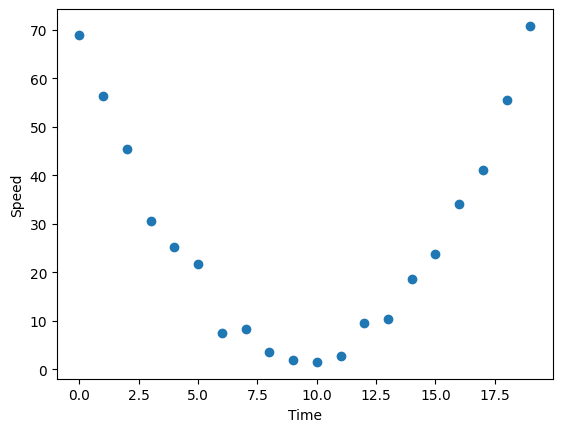

In [36]:
speed=torch.randn(20)*3 + 0.75*(time-9.5)**2+1

plt.scatter(time,speed)
plt.xlabel("Time")
plt.ylabel("Speed")


In [37]:
def f(t,params):
    a,b,c = params
    return a*(t**2)+(b*t)+c

In [38]:
def mse(pred, targets):
    return ((pred-targets)**2).mean()

In [39]:
## Intiialize

params =torch.randn(3).requires_grad_() # pytorch should track those initial random 3 values

## calculating predictions
preds = f(time,params) ## based on the initail params above get prediction

## loss calc
def show_preds(preds, ax=None): 
    if ax is None:ax=plt.subplots()[1] 
    ax.scatter(time, speed) 
    ax.scatter(time, to_np(preds), color='red', label="Predicted") 
    ax.set_ylim(-300,100)

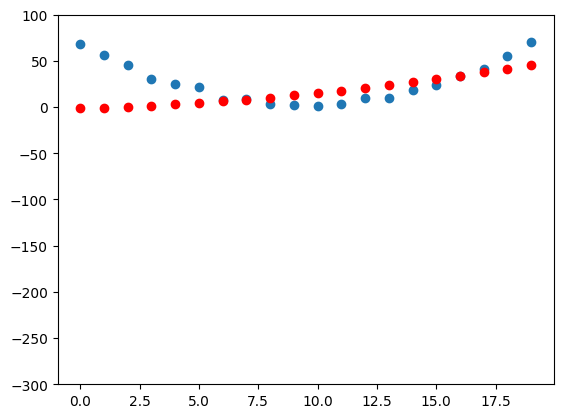

In [40]:
show_preds(preds)

In [41]:
loss=mse(preds,speed)
loss

tensor(683.7678, grad_fn=<MeanBackward0>)

In [42]:
## calculating gradients
loss.backward() ## backpropagation
params.grad



params.grad*1e-5

tensor([-0.0048, -0.0003, -0.0002])

In [43]:
params

tensor([ 0.0912,  0.7395, -1.4802], requires_grad=True)

In [44]:
## Step the weight (optmization) using a lr =0.00001 (1e-5) 
lr = 1e-5
params.data -=lr * params.grad.data
params.grad=None 

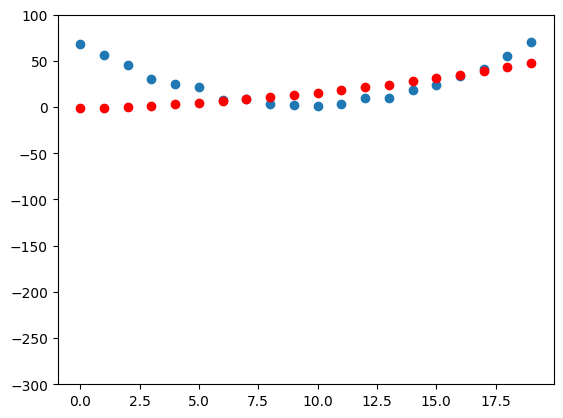

In [45]:
preds=f(time,params)
mse(preds,speed)
show_preds(preds)

In [46]:
def apply_step(params,prn=True): 
    preds = f(time, params) 
    loss = mse(preds, speed) 
    loss.backward() 
    params.data -= lr * params.grad.data 
    params.grad = None 
    if prn: print(loss.item()) 
    return preds

In [47]:
for i in range(10):
    apply_step(params)

682.083740234375
681.7623291015625
681.6986083984375
681.6836547851562
681.677978515625
681.6739501953125
681.67041015625
681.6668090820312
681.6633911132812
681.6597900390625


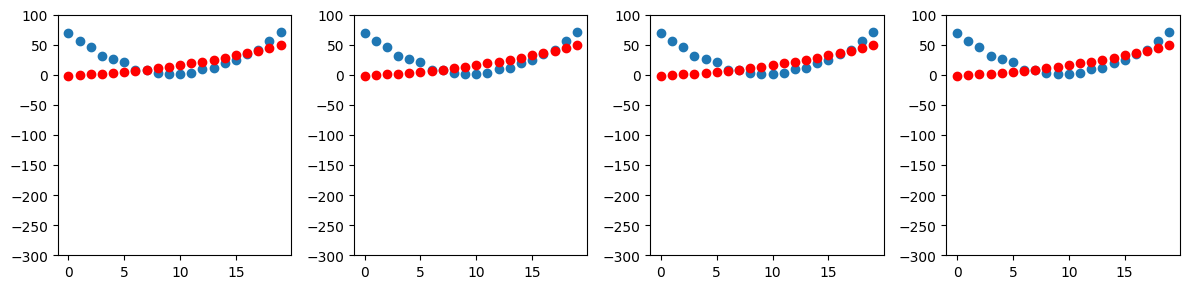

In [48]:
_,axs = plt.subplots(1,4,figsize=(12,3))
for ax in axs: show_preds(apply_step(params, False), ax)
plt.tight_layout()

In [49]:
## Continuing with MNIST

train_x = torch.cat([stacked_three_tensors, stacked_seven_tensors]).view(-1,28*28)
# We need a label for each image. We’ll use 1 for 3s and 0 for 7s: so labels are targets
train_y= tensor([1]*len(three) + [0]*len(Seven)).unsqueeze(1) 


In [50]:
print('Train size:',train_x.shape, "test size:",train_y.shape)

Train size: torch.Size([12396, 784]) test size: torch.Size([12396, 1])


In [51]:
dset=list(zip(train_x,train_y))
x,y=dset[0]
x.shape,y

(torch.Size([784]), tensor([1]))

In [52]:
# doing the same thing for test (validation set)
valid_x = torch.cat([valid_3_tensor, valid_7_tensor]).view(-1, 28*28)
valid_y = tensor([1]*len(valid_3_tensor) + [0]*len(valid_7_tensor)).unsqueeze(1)
valid_dset = list(zip(valid_x,valid_y))

In [53]:
#initialization

def init_params(size, std=1.0):
    return (torch.randn(size)*std).requires_grad_() ## generate random normally distributed values

weights = init_params((28*28,1))

## but weights*pixels for 0 pixels would be 0 so we need to add a bias (y=w*x + b)
bias = init_params(1) 

In [54]:
# calculating a prediction for only first image
(train_x[0]*weights.T).sum() + bias 

tensor([-2.0353], grad_fn=<AddBackward0>)

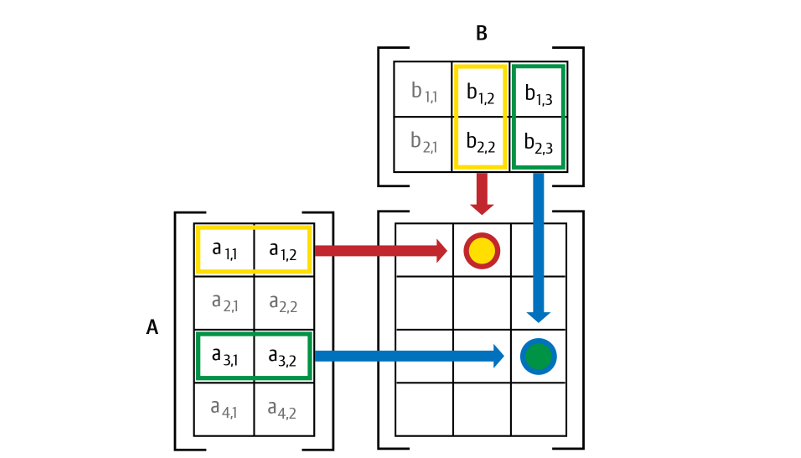

In [55]:
## matrix multiplication
def linear1(xb): 
    return xb@weights + bias
preds =linear1(train_x)


In [56]:
## since we have all outputs (predictions) in preds we cal accuracy for each (using broadcasting)

corrects = (preds>0.0).float()==train_y
corrects[0:10]

tensor([[False],
        [False],
        [False],
        [ True],
        [False],
        [ True],
        [False],
        [False],
        [ True],
        [False]])

In [57]:
corrects.float().mean().item()

0.5969667434692383

In [58]:
weights[0]*= 1.0001

#with torch.no_grad():
    #weights[0] *= 1.0001

RuntimeError: a view of a leaf Variable that requires grad is being used in an in-place operation.

In [59]:
preds = linear1(train_x)
((preds>0.0).float() == train_y).float().mean().item()

0.5969667434692383

In [60]:
def mnist_loss(predictions, targets): 
    return torch.where(targets==1, 1-predictions, predictions).mean()

In [61]:
def mnist_loss(predictions, targets): 
    predictions = predictions.sigmoid() 
    return torch.where(targets==1, 1-predictions, predictions).mean()

In [62]:
coll=range(15)
dl= DataLoader(coll,batch_size=5,shuffle=True)
list(dl) 

[tensor([3, 2, 7, 9, 4]),
 tensor([11, 14,  8, 10,  0]),
 tensor([ 6, 12, 13,  1,  5])]

In [63]:
ds=L(enumerate(string.ascii_lowercase))
ds

[(0, 'a'), (1, 'b'), (2, 'c'), (3, 'd'), (4, 'e'), (5, 'f'), (6, 'g'), (7, 'h'), (8, 'i'), (9, 'j'), (10, 'k'), (11, 'l'), (12, 'm'), (13, 'n'), (14, 'o'), (15, 'p'), (16, 'q'), (17, 'r'), (18, 's'), (19, 't'), (20, 'u'), (21, 'v'), (22, 'w'), (23, 'x'), (24, 'y'), (25, 'z')]

In [64]:
#dataloaders helps to get well organized independent and dependent variables in data
dl=DataLoader(ds,batch_size=6,shuffle=True)
list(dl)

[(tensor([ 8, 18, 25, 15,  2, 14]), ('i', 's', 'z', 'p', 'c', 'o')),
 (tensor([ 7, 10,  0,  1, 19, 22]), ('h', 'k', 'a', 'b', 't', 'w')),
 (tensor([ 9,  5, 12, 23, 16, 17]), ('j', 'f', 'm', 'x', 'q', 'r')),
 (tensor([21,  6, 24, 20, 11,  3]), ('v', 'g', 'y', 'u', 'l', 'd')),
 (tensor([13,  4]), ('n', 'e'))]

## Training loop
for x,y in dl:\
    pred=model(x)\
    loss= loss_func(pred,y)\
    loss.backward()\
    parameters -=parameters.grad*lr
    

In [65]:
#initializing out parameters
weights=init_params((28*28,1))
bias=init_params(1)

In [66]:
#Creating dataloader from dataset
dl=DataLoader(dset, batch_size=256)
xb,yb=first(dl) #for firat batch of 256
xb.shape,yb.shape

(torch.Size([256, 784]), torch.Size([256, 1]))

In [67]:
valid_dl=DataLoader(valid_dset, batch_size=256)
 

In [68]:
# we create test set of 4 for testing
batch =train_x[:4]
batch.shape 

torch.Size([4, 784])

In [69]:
preds=linear1(batch)
preds

tensor([[-4.6044],
        [ 4.7309],
        [-3.6575],
        [ 4.8176]], grad_fn=<AddBackward0>)

In [70]:
loss=mnist_loss(preds,train_y[:4])
loss

tensor(0.4954, grad_fn=<MeanBackward0>)

In [71]:
loss.backward()
weights.grad.shape,weights.grad.mean(),bias.grad

(torch.Size([784, 1]), tensor(-0.0019), tensor([-0.0127]))

In [1]:
def calc_grad(xb,yb, model):
    preds=model(xb)
    loss=mnist_loss(preds,yb)
    loss.backward()
    
calc_grad(batch,train_y[:4],linear1)
weights.grad.mean(),bias.grad

NameError: name 'batch' is not defined

In [73]:
calc_grad(batch,train_y[:4],linear1)
weights.grad.mean(),bias.grad

(tensor(-0.0057), tensor([-0.0382]))

In [74]:
def train_epoch(model,lr,params):
    for xb,yb in dl:
        calc_grad(xb,yb,model)
        for p in params:
            p.data -=p.grad*lr
            p.grad.zero_()

In [75]:
(preds>0.0).float()==train_y[:4]

tensor([[False],
        [ True],
        [False],
        [ True]])

In [76]:
def batch_accuracy(xb,yb):
    preds=xb.sigmoid()
    correct=(preds>0.5)==yb
    return correct.float().mean()

In [77]:
batch_accuracy(linear1(batch),train_y[:4])

tensor(0.5000)

In [78]:
def validate_epoch(model):
    accs=[batch_accuracy(model(xb),yb) for xb,yb in valid_dl]
    return round(torch.stack(accs).mean().item(),4)

In [79]:
validate_epoch(linear1)

0.251

In [80]:
lr =1
params=weights, bias
train_epoch(linear1,lr,params)
validate_epoch(linear1)

0.5001

In [81]:
for i in range(20):
    train_epoch(linear1, lr, params)
    print('validation acc',validate_epoch(linear1), end="")

validation acc 0.6166validation acc 0.791validation acc 0.8862validation acc 0.9213validation acc 0.9364validation acc 0.9457validation acc 0.9491validation acc 0.954validation acc 0.9569validation acc 0.9589validation acc 0.9613validation acc 0.9623validation acc 0.9633validation acc 0.9657validation acc 0.9677validation acc 0.9691validation acc 0.9706validation acc 0.9706validation acc 0.9706validation acc 0.9711

## The above was the manual way but pytorch has an **OPTIMIZER** that would handle this step for us

In [82]:
linear_model=nn.Linear(28*28,1)

#for parameters
w,b=linear_model.parameters()
w.shape, b.shape

(torch.Size([1, 784]), torch.Size([1]))

In [83]:
class BasicOptim:
    def __init__(self,params,lr):
        self.params=list(params)
        self.lr=lr
        
    def step(self,*args, **kwargs):
        for p in self.params:
            p.data-=p.grad.data*self.lr
            
    def zero_grad(self,*arg,**kwargs):
        for p in self.params:
            p.grad =None

opt= BasicOptim(linear_model.parameters(),lr)

In [84]:
def train_epoch(model):
    for xb,yb in dl:
        calc_grad(xb,yb,model)
        opt.step()
        opt.zero_grad()

In [85]:
validate_epoch(linear_model)

0.5166

In [86]:
#Training loop
def train_model(model,epochs):
    for i in range(epochs):
        train_epoch(model)
        print(validate_epoch(model), end="")

train_model(linear_model,20)

0.49320.69190.86280.9170.9360.95020.95790.96330.96580.96820.96970.97060.97410.9750.9760.9770.97750.9780.97850.9785

In [87]:
#Using fastai optmizer (SGD)
linear_model = nn.Linear(28*28,1)
opt = SGD(linear_model.parameters(), lr) #mostly used
train_model(linear_model, 20)


0.49320.91740.79780.90430.93160.94670.95450.96040.96530.96720.96870.97160.97310.9750.97550.97650.97750.97750.9780.9785

In [88]:
## another alternative to train_model

dls=DataLoaders(dl,valid_dl)

learn = Learner(dls, 
                nn.Linear(28*28,1), 
                opt_func=SGD, 
                loss_func=mnist_loss,
                metrics=batch_accuracy)


learn.fit(10,lr=lr)

epoch,train_loss,valid_loss,batch_accuracy,time
0,0.637321,0.502580,0.495584,00:00
1,0.359386,0.287751,0.717861,00:00
2,0.138076,0.156604,0.860648,00:00
3,0.064207,0.098572,0.916585,00:00
4,0.036768,0.073758,0.935721,00:00
5,0.025870,0.059884,0.950932,00:00
6,0.021271,0.051116,0.956820,00:00
7,0.019135,0.045220,0.963690,00:00
8,0.017985,0.041036,0.965162,00:00
9,0.017252,0.037926,0.967615,00:00


<Axes: title={'center': 'learning curve'}, xlabel='steps', ylabel='loss'>

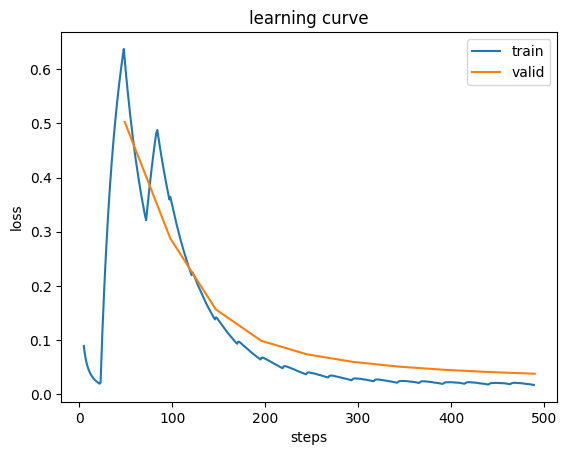

In [89]:
learn.recorder.plot_loss()

## Adding Non-Linearity 

In [92]:
simple_net=nn.Sequential(
    nn.Linear(28*28,30),
    nn.ReLU(),
    nn.Linear(30,1)
)

In [99]:
#?? Learner

In [95]:
learn=Learner(dls,simple_net,
             loss_func=mnist_loss,
             opt_func=SGD,
             metrics=batch_accuracy,
            )

In [96]:
learn.fit(40,0.1) #epochs, lr

epoch,train_loss,valid_loss,batch_accuracy,time
0,0.320682,0.407243,0.505888,00:00
1,0.147607,0.231589,0.798822,00:00
2,0.081450,0.116271,0.916094,00:00
3,0.053412,0.078235,0.940628,00:00
4,0.040479,0.061036,0.956820,00:00
5,0.033906,0.051410,0.962709,00:00
6,0.030146,0.045353,0.965653,00:00
7,0.027713,0.041213,0.966634,00:00
8,0.025964,0.038193,0.970069,00:00
9,0.024609,0.035885,0.970559,00:00


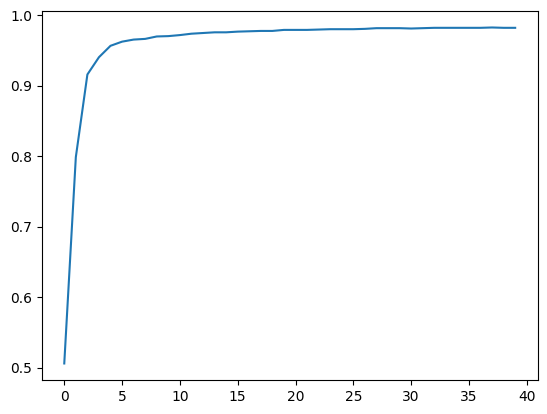

In [97]:
plt.plot(L(learn.recorder.values).itemgot(2))

last accuracy 0.98233562707901


<Axes: title={'center': 'learning curve'}, xlabel='steps', ylabel='loss'>

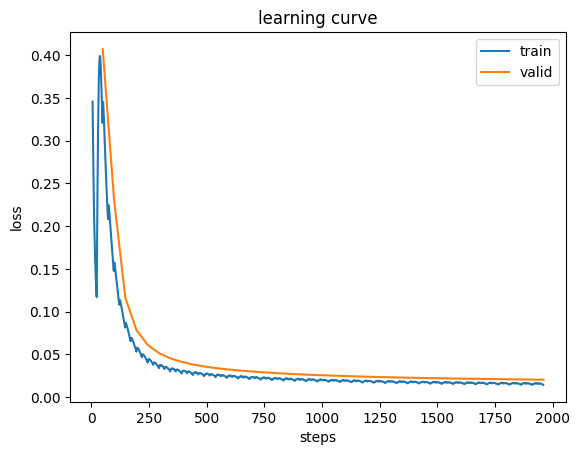

In [102]:
print("last accuracy:",learn.recorder.values[-1][2])
learn.recorder.plot_loss()